# Grover with several solutions (k > 1)

**Question.** What if there are more than one solution?

For example: n = 4 qubits, then N = 16 and correct solutions are k = 1, 2, 3, 4, and 8.

**What theory predicts.** With $k$ solutions the rotation angle per round is bigger,

$$\theta = \arcsin\sqrt{k/N}, \qquad P(r) = \sin^2\big((2r+1)\,\theta\big),$$

so we need **fewer rounds** when there are more solutions (roughly $\frac{\pi}{4}\sqrt{N/k}$).
Two special cases are worth knowing:

- **$k = N/4$ (here $k = 4$):** $\theta = 30^\circ$, so after 1 round the angle is $3\theta = 90^\circ$ and the success probability is **exactly 100%**.
- **$k = N/2$ (here $k = 8$):** $\theta = 45^\circ$, and $\sin^2\big((2r+1)\cdot 45^\circ\big) = 50\%$ for *every* $r$.
  Grover rounds don't help at all. The optimal $r$ is $0$, which is the same as guessing at random (8 out of 16 = 50%).

In [7]:
import os
import numpy as np
import matplotlib.pyplot as plt
from qiskit import transpile
from qiskit_aer import AerSimulator

%run grover_core.ipynb   # loads oracle, diffuser, grover, optimal_iterations, theoretical_success, success_rate

os.makedirs("figures", exist_ok=True)

N_QUBITS = 4
N = 2 ** N_QUBITS
SHOTS = 2048
sim = AerSimulator()
rng = np.random.default_rng(1234)   # gives every run its own seed: reproducible, but independent runs

In [8]:
ORDER = ["1011", "0110", "0001", "1100", "0111", "1000", "0010", "1101",
         "0000", "1111", "0101", "1010", "0011", "1110", "0100", "1001"]
assert sorted(ORDER) == [format(i, "04b") for i in range(N)]   # every state exactly once

K_VALUES = [1, 2, 3, 4, 8]
MARKED = {k: ORDER[:k] for k in K_VALUES}

print(" k | optimal r | theory P(r_opt) | marked states")
for k in K_VALUES:
    r = optimal_iterations(N_QUBITS, k)
    print(f"{k:2d} | {r:9d} | {theoretical_success(N_QUBITS, r, k):15.3f} | {', '.join(MARKED[k])}")

 k | optimal r | theory P(r_opt) | marked states
 1 |         3 |           0.961 | 1011
 2 |         2 |           0.945 | 1011, 0110
 3 |         1 |           0.949 | 1011, 0110, 0001
 4 |         1 |           1.000 | 1011, 0110, 0001, 1100
 8 |         0 |           0.500 | 1011, 0110, 0001, 1100, 0111, 1000, 0010, 1101


## 2. A helper to run one experiment

`run_counts` creates a Grover circuit using the selected marked states and number of rounds, then runs it on a simulator and returns the measurement results. After that, `success_rate` calculates how often we get a correct answer by adding up the counts of all marked states.

In [9]:
def run_counts(marked, r, shots=SHOTS):
    qc = grover(N_QUBITS, marked, r)
    seed = int(rng.integers(2**31))
    return sim.run(transpile(qc, sim), shots=shots, seed_simulator=seed).result().get_counts()



Marked states are drawn in **orange**, all other states in grey.
The dashed line is $1/N$, the probability of each state if we just guessed at random.

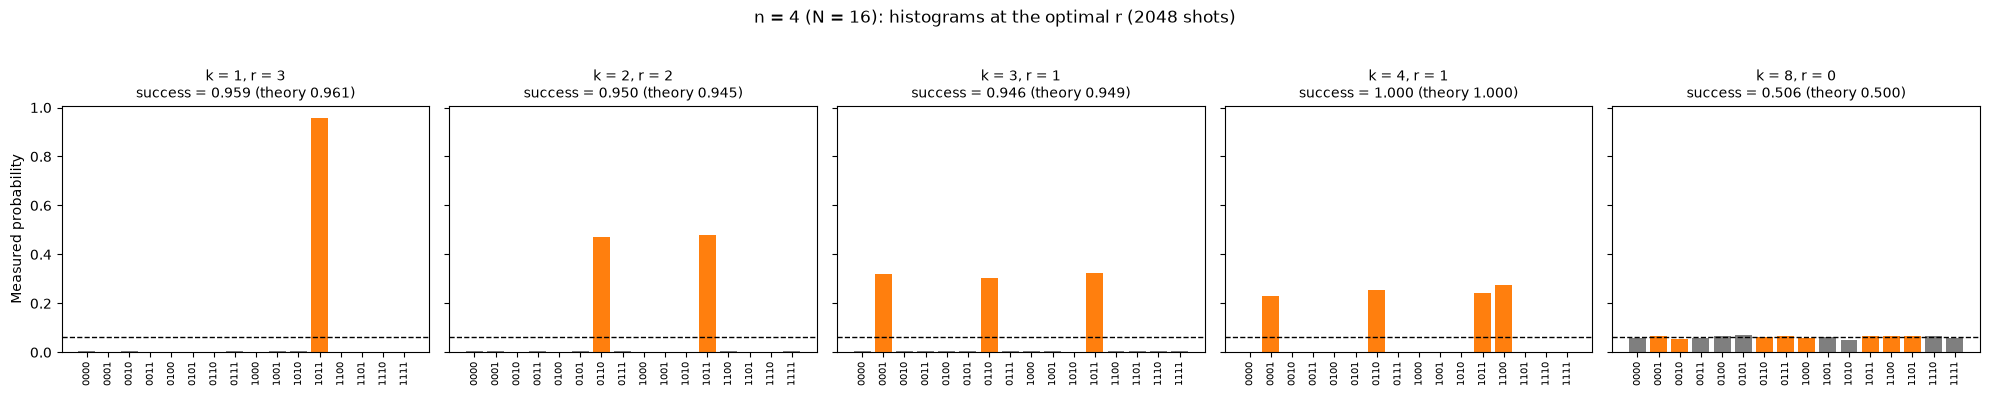

In [10]:
all_states = [format(i, "04b") for i in range(N)]
fig, axes = plt.subplots(1, len(K_VALUES), figsize=(4 * len(K_VALUES), 3.8), sharey=True)
hist_results = {}
for ax, k in zip(axes, K_VALUES):
    r = optimal_iterations(N_QUBITS, k)
    counts = run_counts(MARKED[k], r)
    p = success_rate(counts, MARKED[k], SHOTS)
    hist_results[k] = (r, p)
    probs = [counts.get(s, 0) / SHOTS for s in all_states]
    colors = ["tab:orange" if s in MARKED[k] else "tab:gray" for s in all_states]
    ax.bar(range(N), probs, color=colors)
    ax.axhline(1 / N, color="black", linestyle="--", linewidth=1)
    ax.set_xticks(range(N))
    ax.set_xticklabels(all_states, rotation=90, fontsize=7)
    ax.set_title(f"k = {k}, r = {r}\nsuccess = {p:.3f} (theory {theoretical_success(N_QUBITS, r, k):.3f})", fontsize=10)
axes[0].set_ylabel("Measured probability")
fig.suptitle(f"n = 4 (N = 16): histograms at the optimal r ({SHOTS} shots)", y=1.03)
plt.tight_layout()
plt.savefig("figures/fig_multiple_solutions_histograms.png", dpi=200, bbox_inches="tight")
plt.show()

### Success rate vs. number of rounds



 r | k=1: sim / theory | k=2: sim / theory | k=3: sim / theory | k=4: sim / theory | k=8: sim / theory
 0 | 0.076 / 0.062 | 0.128 / 0.125 | 0.181 / 0.187 | 0.253 / 0.250 | 0.511 / 0.500
 1 | 0.460 / 0.473 | 0.793 / 0.781 | 0.951 / 0.949 | 1.000 / 1.000 | 0.495 / 0.500
 2 | 0.911 / 0.908 | 0.943 / 0.945 | 0.632 / 0.616 | 0.240 / 0.250 | 0.479 / 0.500
 3 | 0.959 / 0.961 | 0.314 / 0.330 | 0.000 / 0.000 | 0.241 / 0.250 | 0.500 / 0.500
 4 | 0.581 / 0.582 | 0.012 / 0.012 | 0.595 / 0.603 | 1.000 / 1.000 | 0.500 / 0.500
 5 | 0.126 / 0.125 | 0.551 / 0.548 | 0.943 / 0.955 | 0.262 / 0.250 | 0.486 / 0.500
 6 | 0.022 / 0.020 | 1.000 / 1.000 | 0.207 / 0.198 | 0.250 / 0.250 | 0.510 / 0.500
 7 | 0.359 / 0.365 | 0.581 / 0.577 | 0.175 / 0.177 | 1.000 / 1.000 | 0.499 / 0.500
 8 | 0.835 / 0.836 | 0.021 / 0.019 | 0.955 / 0.943 | 0.252 / 0.250 | 0.495 / 0.500


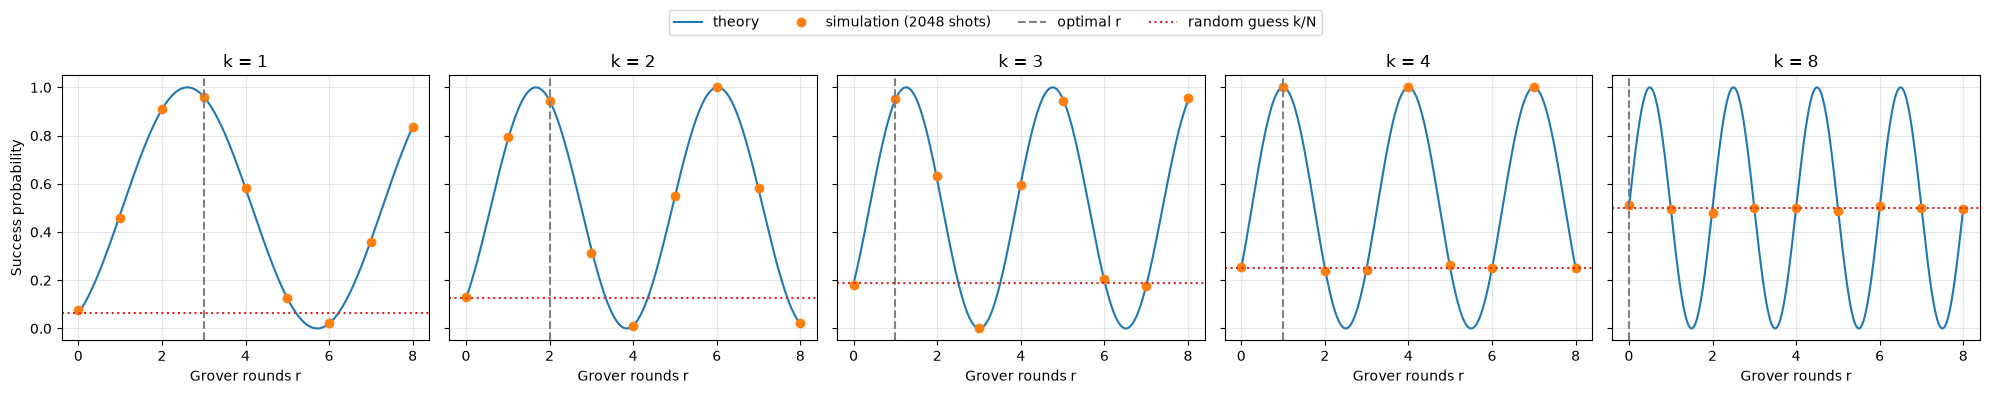

In [11]:
R_MAX = 8
rs = list(range(R_MAX + 1))
fine_r = np.linspace(0, R_MAX, 400)

sweep = {}
for k in K_VALUES:
    sweep[k] = [success_rate(run_counts(MARKED[k], r), MARKED[k], SHOTS) for r in rs]

print(" r | " + " | ".join(f"k={k}: sim / theory" for k in K_VALUES))
for i, r in enumerate(rs):
    print(f"{r:2d} | " + " | ".join(f"{sweep[k][i]:.3f} / {theoretical_success(N_QUBITS, r, k):.3f}" for k in K_VALUES))

fig, axes = plt.subplots(1, len(K_VALUES), figsize=(4 * len(K_VALUES), 3.6), sharey=True)
for ax, k in zip(axes, K_VALUES):
    theta = np.arcsin(np.sqrt(k / N))
    ax.plot(fine_r, np.sin((2 * fine_r + 1) * theta) ** 2, "-", label="theory")
    ax.plot(rs, sweep[k], "o", label=f"simulation ({SHOTS} shots)")
    ax.axvline(optimal_iterations(N_QUBITS, k), color="gray", linestyle="--", label="optimal r")
    ax.axhline(k / N, color="tab:red", linestyle=":", label="random guess k/N")
    ax.set_title(f"k = {k}")
    ax.set_xlabel("Grover rounds r")
    ax.grid(alpha=0.3)
axes[0].set_ylabel("Success probability")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=4, bbox_to_anchor=(0.5, 1.1))
plt.tight_layout()
plt.savefig("figures/fig_multiple_solutions_vs_rounds.png", dpi=200, bbox_inches="tight")
plt.show()

### Optimal number of rounds vs k

 k | optimal r | theory | simulation
 1 |         3 | 0.961  | 0.957
 2 |         2 | 0.945  | 0.953
 3 |         1 | 0.949  | 0.947
 4 |         1 | 1.000  | 1.000
 5 |         1 | 0.957  | 0.958
 6 |         1 | 0.844  | 0.858
 7 |         1 | 0.684  | 0.657
 8 |         0 | 0.500  | 0.492
 9 |         0 | 0.562  | 0.557
10 |         0 | 0.625  | 0.647
11 |         0 | 0.688  | 0.683
12 |         0 | 0.750  | 0.770
13 |         0 | 0.812  | 0.807
14 |         0 | 0.875  | 0.867
15 |         0 | 0.938  | 0.933
16 |         0 | 1.000  | 1.000


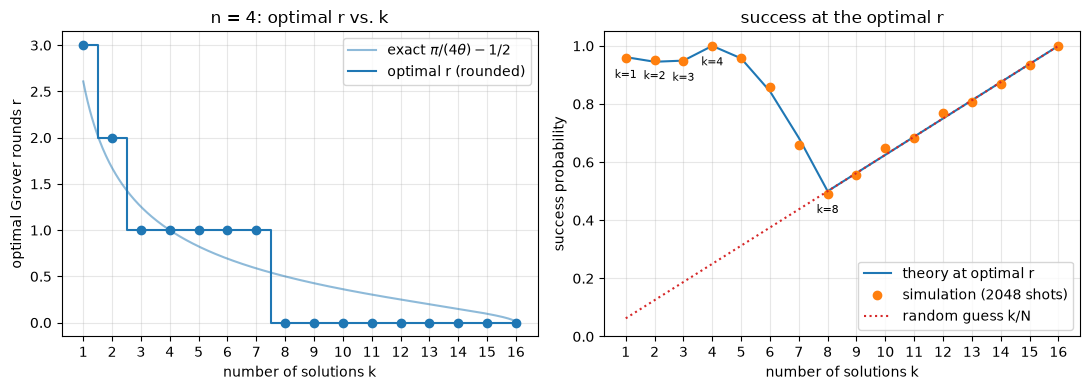

In [12]:
ks = list(range(1, N + 1))
k_fine = np.linspace(1, N, 400)
r_exact = np.pi / (4 * np.arcsin(np.sqrt(k_fine / N))) - 0.5
r_opt = [optimal_iterations(N_QUBITS, k) for k in ks]
p_theory = [theoretical_success(N_QUBITS, r, k) for k, r in zip(ks, r_opt)]
p_sim = [success_rate(run_counts(ORDER[:k], r), ORDER[:k], SHOTS) for k, r in zip(ks, r_opt)]

print(" k | optimal r | theory | simulation")
for k, r, pt, ps in zip(ks, r_opt, p_theory, p_sim):
    print(f"{k:2d} | {r:9d} | {pt:.3f}  | {ps:.3f}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
ax1.plot(k_fine, r_exact, "-", color="tab:blue", alpha=0.5, label=r"exact $\pi/(4\theta) - 1/2$")
ax1.step(ks, r_opt, where="mid", color="tab:blue", label="optimal r (rounded)")
ax1.plot(ks, r_opt, "o", color="tab:blue")
ax1.set_xlabel("number of solutions k")
ax1.set_ylabel("optimal Grover rounds r")
ax1.set_xticks(ks)
ax1.grid(alpha=0.3)
ax1.legend()
ax1.set_title("n = 4: optimal r vs. k")

ax2.plot(ks, p_theory, "-", label="theory at optimal r")
ax2.plot(ks, p_sim, "o", label=f"simulation ({SHOTS} shots)")
ax2.plot(ks, [k / N for k in ks], ":", color="tab:red", label="random guess k/N")
for k in K_VALUES:
    ax2.annotate(f"k={k}", (k, p_sim[k - 1]), textcoords="offset points", xytext=(0, -14), ha="center", fontsize=8)
ax2.set_xlabel("number of solutions k")
ax2.set_ylabel("success probability")
ax2.set_xticks(ks)
ax2.set_ylim(0, 1.05)
ax2.grid(alpha=0.3)
ax2.legend(loc="lower right")
ax2.set_title("success at the optimal r")
plt.tight_layout()
plt.savefig("figures/fig_multiple_solutions_optimal_r.png", dpi=200, bbox_inches="tight")
plt.show()